In [1]:
import pandas as pd

df = pd.read_csv("dataset.csv")

genres = ["pop", "rock", "alt-rock", "indie", "indie-pop"]

filtered_df = df[df["track_genre"].isin(genres)].copy()

print("Original rows:", len(df))
print("Filtered rows:", len(filtered_df))

filtered_df.head()

Original rows: 114000
Filtered rows: 5000


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
2000,2000,5E30LdtzQTGqRvNd7l6kG5,The Neighbourhood,Wiped Out!,Daddy Issues,87,260173,False,0.588,0.521,...,-9.461,1,0.0329,0.0678,0.149000,0.123,0.337,85.012,4,alt-rock
2001,2001,2Y0iGXY6m6immVb2ktbseM,MGMT,Little Dark Age,Little Dark Age,83,299960,False,0.705,0.712,...,-6.156,1,0.0385,0.0102,0.000855,0.100,0.620,97.512,4,alt-rock
2002,2002,2K7xn816oNHJZ0aVqdQsha,The Neighbourhood,Hard To Imagine The Neighbourhood Ever Changing,Softcore,86,206280,False,0.575,0.568,...,-5.509,0,0.0300,0.0484,0.000417,0.286,0.370,93.986,4,alt-rock
2003,2003,2QjOHCTQ1Jl3zawyYOpxh6,The Neighbourhood,I Love You.,Sweater Weather,93,240400,False,0.612,0.807,...,-2.810,1,0.0336,0.0495,0.017700,0.101,0.398,124.053,4,alt-rock
2004,2004,7zwn1eykZtZ5LODrf7c0tS,The Neighbourhood,Hard To Imagine The Neighbourhood Ever Changing,You Get Me So High,83,153000,False,0.551,0.881,...,-6.099,0,0.0542,0.1860,0.079100,0.152,0.387,88.036,4,alt-rock


In [2]:
filtered_df.to_csv("spotify_5_genres.csv", index=False)

In [3]:

print("Total rows:", len(filtered_df))
print("Unique tracks:", filtered_df["track_id"].nunique())

genre_counts = filtered_df.groupby("track_id")["track_genre"].nunique()

print("Single-genre tracks:", (genre_counts == 1).sum())
print("Multi-genre tracks:", (genre_counts >= 2).sum())


Total rows: 5000
Unique tracks: 4088
Single-genre tracks: 3281
Multi-genre tracks: 807


In [4]:
track_genres = (
    filtered_df.groupby("track_id")["track_genre"]
    .unique()
    .reset_index()
)

track_genres.head(10)

,track_id,track_genre
0,003vvx7Niy0yvhvHt4a68B,"[alt-rock, rock]"
1,00B7SBwrjbycLMOgAmeIU8,[alt-rock]
2,00YwP3wJWiG8IxAA7OS9lo,"[indie-pop, indie]"
3,00ZGWtUFiGqWuFd7i4OeZV,[rock]
4,00gxx5tCbWPxr76vGNED8B,"[alt-rock, indie-pop, indie]"
5,00toEUNl6yPNBZdnIivdFk,[rock]
6,014DA3BdnmD3kI5pBogH7c,[indie-pop]
7,014SIjoLDG1Ku19c5FlDYh,[rock]
8,019GjjVqU4lNg4QnZzRjUd,[alt-rock]
9,01MVOl9KtVTNfFiBU9I7dc,[indie-pop]


In [5]:
import rdflib
print(rdflib.__version__)

7.6.0


In [6]:
import pandas as pd
from rdflib import Graph, Namespace, URIRef, Literal, RDF, XSD

df = pd.read_csv("spotify_5_genres.csv")

print("Rows:", len(df))
print("Unique tracks:", df["track_id"].nunique())

Rows: 5000
Unique tracks: 4088


In [7]:
g = Graph()

SPOTIFY = Namespace(
    "http://www.example.org/spotify-genre-ontology#"
)

g.bind("spotify", SPOTIFY)

print("Graph created!")

Graph created!


In [8]:

from rdflib import Graph, Namespace, RDF

ontology = Graph()
ontology.parse("ontology.ttl", format="turtle")

SPOTIFY = Namespace("http://www.semanticweb.org/vishwasdubey/ontologies/2026/9/untitled-ontology-5#")

print("Ontology triples:", len(ontology))
print("MusicTrack exists:", (SPOTIFY.MusicTrack, RDF.type, None) in ontology)
print("hasGenre exists:", (SPOTIFY.hasGenre, RDF.type, None) in ontology)


Ontology triples: 103
MusicTrack exists: False
hasGenre exists: False


In [9]:

for subject, predicate, obj in ontology:
    if "MusicTrack" in str(subject) or "hasGenre" in str(subject):
        print(subject)


http://www.semanticweb.org/vishwasdubey/ontologies/2026/9/untitled-ontology-5/MusicTrack
http://www.semanticweb.org/vishwasdubey/ontologies/2026/9/untitled-ontology-5/hasGenre
http://www.semanticweb.org/vishwasdubey/ontologies/2026/9/untitled-ontology-5/MusicTrack
http://www.semanticweb.org/vishwasdubey/ontologies/2026/9/untitled-ontology-5/hasGenre
http://www.semanticweb.org/vishwasdubey/ontologies/2026/9/untitled-ontology-5/hasGenre


In [10]:

from rdflib import Graph, RDF, OWL

# Reload your ontology
ontology = Graph()
ontology.parse("Ontology.ttl", format="turtle")

# Find the actual class and property IRIs
for subject in set(ontology.subjects()):
    if str(subject).endswith(("#MusicTrack", "#hasGenre")):
        print("Found:", subject)

# Check declarations by their actual names
for subject in set(ontology.subjects()):
    if str(subject).endswith("#MusicTrack"):
        print("MusicTrack types:", list(ontology.objects(subject, RDF.type)))
    if str(subject).endswith("#hasGenre"):
        print("hasGenre types:", list(ontology.objects(subject, RDF.type)))


In [11]:
from rdflib import Graph

ontology = Graph()
ontology.parse("Ontology.ttl", format="turtle")

print("Total triples:", len(ontology))

print("\nFirst 10 triples:")
for triple in list(ontology)[:10]:
    print(triple)

Total triples: 103

First 10 triples:
(rdflib.term.URIRef('http://www.semanticweb.org/vishwasdubey/ontologies/2026/9/untitled-ontology-5/performedBy'), rdflib.term.URIRef('http://www.w3.org/1999/02/22-rdf-syntax-ns#type'), rdflib.term.URIRef('http://www.w3.org/2002/07/owl#ObjectProperty'))
(rdflib.term.URIRef('http://www.semanticweb.org/vishwasdubey/ontologies/2026/9/untitled-ontology-5/Indie'), rdflib.term.URIRef('http://www.w3.org/1999/02/22-rdf-syntax-ns#type'), rdflib.term.URIRef('http://www.semanticweb.org/vishwasdubey/ontologies/2026/9/untitled-ontology-5/Genre'))
(rdflib.term.URIRef('http://www.semanticweb.org/vishwasdubey/ontologies/2026/9/untitled-ontology-5/SingleGenreTrack'), rdflib.term.URIRef('http://www.w3.org/2000/01/rdf-schema#subClassOf'), rdflib.term.URIRef('http://www.semanticweb.org/vishwasdubey/ontologies/2026/9/untitled-ontology-5/MusicTrack'))
(rdflib.term.URIRef('http://www.semanticweb.org/vishwasdubey/ontologies/2026/9/untitled-ontology-5/belongsToAlbum'), rdfl

In [12]:
from rdflib import Graph, Namespace, RDF

ontology = Graph()
ontology.parse("Ontology.ttl", format="turtle")

SPOTIFY = Namespace(
    "http://www.semanticweb.org/vishwasdubey/ontologies/2026/9/untitled-ontology-5/"
)

print("Ontology triples:", len(ontology))
print("MusicTrack exists:", (SPOTIFY.MusicTrack, RDF.type, None) in ontology)
print("hasGenre exists:", (SPOTIFY.hasGenre, RDF.type, None) in ontology)

Ontology triples: 103
MusicTrack exists: True
hasGenre exists: True


In [13]:
df[[
    "track_id",
    "track_name",
    "artists",
    "album_name",
    "track_genre",
    "popularity"
]].head(10)

,track_id,track_name,artists,album_name,track_genre,popularity
0,5E30LdtzQTGqRvNd7l6kG5,Daddy Issues,The Neighbourhood,Wiped Out!,alt-rock,87
1,2Y0iGXY6m6immVb2ktbseM,Little Dark Age,MGMT,Little Dark Age,alt-rock,83
2,2K7xn816oNHJZ0aVqdQsha,Softcore,The Neighbourhood,Hard To Imagine The Neighbourhood Ever Changing,alt-rock,86
3,2QjOHCTQ1Jl3zawyYOpxh6,Sweater Weather,The Neighbourhood,I Love You.,alt-rock,93
4,7zwn1eykZtZ5LODrf7c0tS,You Get Me So High,The Neighbourhood,Hard To Imagine The Neighbourhood Ever Changing,alt-rock,83
5,7vguMCv8uVuZLiQJ156u3Z,Play with Fire (feat. Yacht Money),Sam Tinnesz;Yacht Money,Play with Fire (feat. Yacht Money),alt-rock,76
6,4gHnSNHs8RyVukKoWdS99f,Something In The Way,Nirvana,Nevermind (Remastered),alt-rock,76
7,0y1QJc3SJVPKJ1OvFmFqe6,Way down We Go,KALEO,A/B,alt-rock,78
8,6rrKbzJGGDlSZgLphopS49,Unstoppable,The Score,ATLAS,alt-rock,73
9,4CeeEOM32jQcH3eN9Q2dGj,Smells Like Teen Spirit,Nirvana,Nevermind (Remastered),alt-rock,83


In [14]:
from rdflib import RDF, OWL

genres = ["Pop", "Rock", "AltRock", "Indie", "IndiePop"]

for genre in genres:
    genre_uri = SPOTIFY[genre]
    exists = (genre_uri, RDF.type, SPOTIFY.Genre) in ontology
    print(genre, ":", exists)

Pop : True
Rock : True
AltRock : True
Indie : True
IndiePop : True


In [15]:
from rdflib import Graph, RDF, Literal, XSD

instances = Graph()
instances.bind("spotify", SPOTIFY)

track = SPOTIFY["ExampleTrack"]

instances.add((track, RDF.type, SPOTIFY.MusicTrack))
instances.add((track, SPOTIFY.hasGenre, SPOTIFY.Rock))
instances.add((track, SPOTIFY.hasGenre, SPOTIFY.Indie))
instances.add((track, SPOTIFY.hasPopularity, Literal(85, datatype=XSD.integer)))

print("Number of triples:", len(instances))

Number of triples: 4


In [16]:
instances.serialize(
    destination="instances.ttl",
    format="turtle"
)

print("instances.ttl created!")

instances.ttl created!


In [17]:
# Check whether repeated track IDs have different popularity values
popularity_counts = df.groupby("track_id")["popularity"].nunique()

print(
    "Tracks with conflicting popularity scores:",
    (popularity_counts > 1).sum()
)

Tracks with conflicting popularity scores: 36


In [18]:
# Calculate one average popularity score for each track
track_popularity = (
    df.groupby("track_id")["popularity"]
    .mean()
    .round()
    .astype(int)
)

print("Unique tracks:", len(track_popularity))
print(track_popularity.head())

Unique tracks: 4088
track_id
003vvx7Niy0yvhvHt4a68B    86
00B7SBwrjbycLMOgAmeIU8    66
00YwP3wJWiG8IxAA7OS9lo    47
00ZGWtUFiGqWuFd7i4OeZV     0
00gxx5tCbWPxr76vGNED8B     0
Name: popularity, dtype: int64


In [19]:
track_genres = (
    df.groupby("track_id")["track_genre"]
    .unique()
)

print("Unique tracks:", len(track_genres))
print("\nFirst five tracks and their genres:")

for track_id, genres in track_genres.head().items():
    print(track_id, "→", list(genres))

Unique tracks: 4088

First five tracks and their genres:
003vvx7Niy0yvhvHt4a68B → ['alt-rock', 'rock']
00B7SBwrjbycLMOgAmeIU8 → ['alt-rock']
00YwP3wJWiG8IxAA7OS9lo → ['indie-pop', 'indie']
00ZGWtUFiGqWuFd7i4OeZV → ['rock']
00gxx5tCbWPxr76vGNED8B → ['alt-rock', 'indie-pop', 'indie']


In [20]:
# Select the first track in your dataset
sample_id = df["track_id"].iloc[0]

# Display its information
df[df["track_id"] == sample_id][
    ["track_id", "track_name", "artists", "album_name",
     "track_genre", "popularity"]
]

,track_id,track_name,artists,album_name,track_genre,popularity
0,5E30LdtzQTGqRvNd7l6kG5,Daddy Issues,The Neighbourhood,Wiped Out!,alt-rock,87
4100,5E30LdtzQTGqRvNd7l6kG5,Daddy Issues,The Neighbourhood,Wiped Out!,rock,87


In [21]:

from rdflib import Graph, RDF, Literal, XSD

real_instances = Graph()
real_instances.bind("spotify", SPOTIFY)

track_id = df["track_id"].iloc[0]
track_uri = SPOTIFY["track/" + track_id]

print("Track URI:", track_uri)


Track URI: http://www.semanticweb.org/vishwasdubey/ontologies/2026/9/untitled-ontology-5/track/5E30LdtzQTGqRvNd7l6kG5


In [22]:

# Identify the track as a MusicTrack
real_instances.add((track_uri, RDF.type, SPOTIFY.MusicTrack))

# Add the song's name
real_instances.add((
    track_uri,
    SPOTIFY.hasTrackName,
    Literal("Daddy Issues")
))

# Add its popularity score
real_instances.add((
    track_uri,
    SPOTIFY.hasPopularity,
    Literal(87, datatype=XSD.integer)
))

print("Triples created:", len(real_instances))


Triples created: 3


In [23]:

real_instances.add((
    track_uri,
    SPOTIFY.hasGenre,
    SPOTIFY.AltRock
))

real_instances.add((
    track_uri,
    SPOTIFY.hasGenre,
    SPOTIFY.Rock
))

print("Triples created:", len(real_instances))


Triples created: 5


In [24]:
# Create unique identifiers
artist_uri = SPOTIFY["artist/TheNeighbourhood"]
album_uri = SPOTIFY["album/WipedOut"]

# Identify the artist and album
real_instances.add((artist_uri, RDF.type, SPOTIFY.Artist))
real_instances.add((album_uri, RDF.type, SPOTIFY.Album))

# Connect the song to its artist and album
real_instances.add((track_uri, SPOTIFY.performedBy, artist_uri))
real_instances.add((track_uri, SPOTIFY.belongsToAlbum, album_uri))

print("Triples created:", len(real_instances))

Triples created: 9


In [25]:
print("Total triples:", len(real_instances))

print("\nTriples for Daddy Issues:")
for predicate, obj in real_instances.predicate_objects(track_uri):
    print(predicate.split("/")[-1], "→", obj.split("/")[-1])

Total triples: 9

Triples for Daddy Issues:
22-rdf-syntax-ns#type → MusicTrack
hasTrackName → Daddy Issues
hasPopularity → 87
hasGenre → AltRock
hasGenre → Rock
performedBy → TheNeighbourhood
belongsToAlbum → WipedOut


In [26]:
print("Unique tracks:", df["track_id"].nunique())
print("Unique artist fields:", df["artists"].nunique())
print("Unique album names:", df["album_name"].nunique())

print("\nMissing values:")
print(
    df[["track_id", "track_name", "artists", "album_name"]]
    .isna().sum()
)

Unique tracks: 4088
Unique artist fields: 1523
Unique album names: 2114

Missing values:
track_id      0
track_name    0
artists       0
album_name    0
dtype: int64


In [27]:
from rdflib import Graph, RDF, Literal, XSD

full_instances = Graph()
full_instances.bind("spotify", SPOTIFY)

genre_mapping = {
    "pop": "Pop",
    "rock": "Rock",
    "alt-rock": "AltRock",
    "indie": "Indie",
    "indie-pop": "IndiePop"
}

In [28]:
for track_id, group in df.groupby("track_id"):

    track_uri = SPOTIFY["track/" + track_id]
    track_name = group["track_name"].iloc[0]

    full_instances.add((
        track_uri, RDF.type, SPOTIFY.MusicTrack
    ))

    full_instances.add((
        track_uri,
        SPOTIFY.hasTrackName,
        Literal(track_name)
    ))

    full_instances.add((
        track_uri,
        SPOTIFY.hasPopularity,
        Literal(int(track_popularity[track_id]), datatype=XSD.integer)
    ))

    for genre in group["track_genre"].unique():
        genre_uri = SPOTIFY[genre_mapping[genre]]

        full_instances.add((
            track_uri,
            SPOTIFY.hasGenre,
            genre_uri
        ))

print("Total triples:", len(full_instances))

Total triples: 17253


In [29]:
print("Track individuals:",
      len(set(full_instances.subjects(RDF.type, SPOTIFY.MusicTrack))))

print("Genre relationships:",
      len(list(full_instances.triples((None, SPOTIFY.hasGenre, None)))))

print("Total RDF triples:", len(full_instances))

Track individuals: 4088
Genre relationships: 4989
Total RDF triples: 17253


In [30]:
full_instances.serialize(
    destination="instances.ttl",
    format="turtle"
)

print("instances.ttl saved!")

instances.ttl saved!


In [31]:

from urllib.parse import quote

def make_uri(category, name):
    return SPOTIFY[category + "/" + quote(str(name).strip(), safe="")]

# Example
print(make_uri("artist", "The Neighbourhood"))


http://www.semanticweb.org/vishwasdubey/ontologies/2026/9/untitled-ontology-5/artist/The%20Neighbourhood


In [32]:

for track_id, group in df.groupby("track_id"):

    track_uri = SPOTIFY["track/" + track_id]
    row = group.iloc[0]

    # Add artists
    for artist_name in str(row["artists"]).split(";"):
        artist_name = artist_name.strip()

        if artist_name:
            artist_uri = make_uri("artist", artist_name)

            full_instances.add((
                artist_uri, RDF.type, SPOTIFY.Artist
            ))

            full_instances.add((
                track_uri, SPOTIFY.performedBy, artist_uri
            ))

    # Add album
    album_name = str(row["album_name"]).strip()

    if album_name:
        album_uri = make_uri(
            "album",
            str(row["artists"]) + "/" + album_name
        )

        full_instances.add((
            album_uri, RDF.type, SPOTIFY.Album
        ))

        full_instances.add((
            track_uri, SPOTIFY.belongsToAlbum, album_uri
        ))

print("Total triples:", len(full_instances))


Total triples: 31762


In [33]:

full_instances.serialize(
    destination="instances.ttl",
    format="turtle"
)

print("Updated instances.ttl saved!")

print("Artists:",
      len(set(full_instances.subjects(RDF.type, SPOTIFY.Artist))))

print("Albums:",
      len(set(full_instances.subjects(RDF.type, SPOTIFY.Album))))

print("Total triples:", len(full_instances))


Updated instances.ttl saved!
Artists: 1619
Albums: 3419
Total triples: 31762


In [34]:

from rdflib import Graph

kg = Graph()

kg.parse("Ontology.ttl", format="turtle")
kg.parse("instances.ttl", format="turtle")

print("Combined KG triples:", len(kg))


Combined KG triples: 31865


In [35]:

query = """
PREFIX spotify: <http://www.semanticweb.org/vishwasdubey/ontologies/2026/9/untitled-ontology-5/>

SELECT ?genre (COUNT(DISTINCT ?track) AS ?trackCount)
WHERE {
    ?track a spotify:MusicTrack .
    ?track spotify:hasGenre ?genre .
}
GROUP BY ?genre
ORDER BY DESC(?trackCount)
"""

results = kg.query(query)

for row in results:
    print(str(row.genre).split("/")[-1], ":", row.trackCount)


Rock : 1001
IndiePop : 1000
AltRock : 999
Indie : 998
Pop : 993


In [36]:
print("full_instances genre relationships:",
      len(set(full_instances.triples(
          (None, SPOTIFY.hasGenre, None)
      ))))

print("Combined KG genre relationships:",
      len(set(kg.triples(
          (None, SPOTIFY.hasGenre, None)
      ))))

full_instances genre relationships: 4989
Combined KG genre relationships: 4991


In [37]:
# Find TestSong1
test_song = SPOTIFY.TestSong1

# Remove all statements where TestSong1 is the subject
kg.remove((test_song, None, None))

print("Genre relationships:",
      len(list(kg.triples((None, SPOTIFY.hasGenre, None)))))

Genre relationships: 4989


In [38]:
print("Real Spotify tracks:",
      len(set(kg.subjects(RDF.type, SPOTIFY.MusicTrack))))

print("Genre relationships:",
      len(set(kg.triples((None, SPOTIFY.hasGenre, None)))))

Real Spotify tracks: 4088
Genre relationships: 4989


In [39]:

query_cq1 = """
PREFIX spotify: <http://www.semanticweb.org/vishwasdubey/ontologies/2026/9/untitled-ontology-5/>

SELECT ?genre1 ?genre2 (COUNT(DISTINCT ?track) AS ?sharedTracks)
WHERE {
    ?track a spotify:MusicTrack .
    ?track spotify:hasGenre ?genre1 .
    ?track spotify:hasGenre ?genre2 .

    FILTER(STR(?genre1) < STR(?genre2))
}
GROUP BY ?genre1 ?genre2
ORDER BY DESC(?sharedTracks)
"""

results_cq1 = kg.query(query_cq1)

for row in results_cq1:
    genre1 = str(row.genre1).split("/")[-1]
    genre2 = str(row.genre2).split("/")[-1]
    print(genre1, "-", genre2, ":", row.sharedTracks)


Indie - IndiePop : 579
AltRock - Rock : 164
Indie - Rock : 92
AltRock - Indie : 45
IndiePop - Rock : 42
AltRock - IndiePop : 34
Indie - Pop : 18
IndiePop - Pop : 18
Pop - Rock : 7
AltRock - Pop : 1


In [40]:

import pandas as pd

# Number of unique tracks per genre
genre_sizes = {
    "Rock": 1000,
    "IndiePop": 1000,
    "AltRock": 999,
    "Indie": 998,
    "Pop": 993
}

overlap_data = []

for row in kg.query(query_cq1):
    genre1 = str(row.genre1).split("/")[-1]
    genre2 = str(row.genre2).split("/")[-1]
    shared = int(row.sharedTracks)

    union = genre_sizes[genre1] + genre_sizes[genre2] - shared
    percentage = shared / union * 100

    overlap_data.append({
        "Genre Pair": f"{genre1} / {genre2}",
        "Shared Tracks": shared,
        "Overlap (%)": round(percentage, 2)
    })

overlap_df = pd.DataFrame(overlap_data)
overlap_df = overlap_df.sort_values("Overlap (%)", ascending=False)

display(overlap_df)


,Genre Pair,Shared Tracks,Overlap (%)
0,Indie / IndiePop,579,40.80
1,AltRock / Rock,164,8.94
2,Indie / Rock,92,4.83
3,AltRock / Indie,45,2.31
4,IndiePop / Rock,42,2.15
5,AltRock / IndiePop,34,1.73
6,Indie / Pop,18,0.91
7,IndiePop / Pop,18,0.91
8,Pop / Rock,7,0.35
9,AltRock / Pop,1,0.05


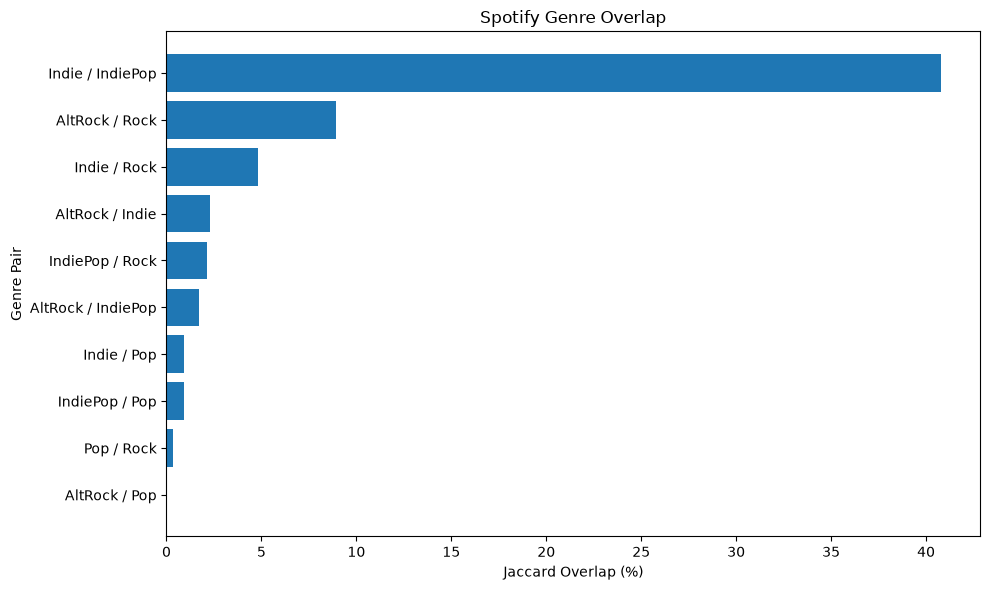

In [41]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    overlap_df["Genre Pair"],
    overlap_df["Overlap (%)"]
)

plt.xlabel("Jaccard Overlap (%)")
plt.ylabel("Genre Pair")
plt.title("Spotify Genre Overlap")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [42]:
plt.savefig("genre_overlap.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [43]:
query_cq2 = """
PREFIX spotify: <http://www.semanticweb.org/vishwasdubey/ontologies/2026/9/untitled-ontology-5/>

SELECT ?genreGroup (COUNT(?track) AS ?trackCount)
       (AVG(?popularity) AS ?averagePopularity)
WHERE {
    {
        SELECT ?track ?popularity
               (COUNT(DISTINCT ?genre) AS ?genreCount)
        WHERE {
            ?track a spotify:MusicTrack .
            ?track spotify:hasGenre ?genre .
            ?track spotify:hasPopularity ?popularity .
        }
        GROUP BY ?track ?popularity
    }

    BIND(
        IF(?genreCount >= 2, "Multi-genre", "Single-genre")
        AS ?genreGroup
    )
}
GROUP BY ?genreGroup
"""
results_cq2 = kg.query(query_cq2)

for row in results_cq2:
    print(
        row.genreGroup,
        "| Tracks:", row.trackCount,
        "| Average popularity:", round(float(row.averagePopularity), 2)
    )

Multi-genre | Tracks: 807 | Average popularity: 37.83
Single-genre | Tracks: 3281 | Average popularity: 34.98


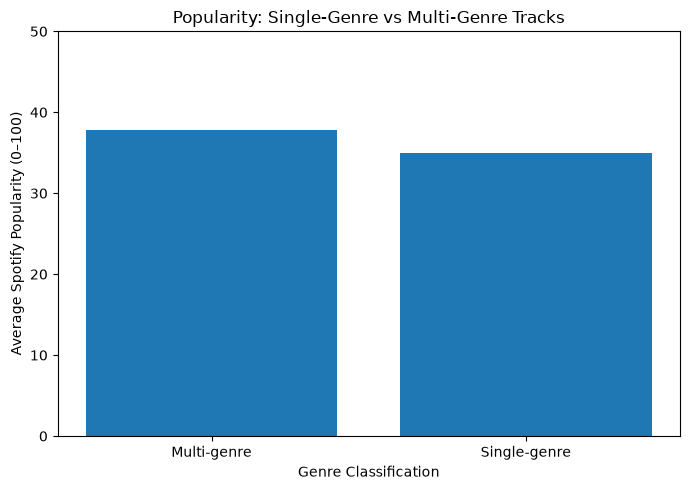

In [44]:

import pandas as pd
import matplotlib.pyplot as plt

cq2_data = []

for row in results_cq2:
    cq2_data.append({
        "Group": str(row.genreGroup),
        "Tracks": int(row.trackCount),
        "Average Popularity": float(row.averagePopularity)
    })

cq2_df = pd.DataFrame(cq2_data)

plt.figure(figsize=(7, 5))
plt.bar(cq2_df["Group"], cq2_df["Average Popularity"])

plt.ylabel("Average Spotify Popularity (0–100)")
plt.xlabel("Genre Classification")
plt.title("Popularity: Single-Genre vs Multi-Genre Tracks")
plt.ylim(0, 50)

plt.tight_layout()
plt.savefig("genre_popularity.png", dpi=300, bbox_inches="tight")
plt.show()


In [45]:
# Find a multi-genre track with popularity >= 70
eligible_ids = [
    track_id
    for track_id, genres in track_genres.items()
    if len(genres) >= 2 and track_popularity[track_id] >= 70
]

print("Qualifying tracks:", len(eligible_ids))

sample_id = eligible_ids[0]

display(
    df[df["track_id"] == sample_id][
        ["track_name", "artists", "track_genre", "popularity"]
    ]
)

print("Track ID:", sample_id)

Qualifying tracks: 183


,track_name,artists,track_genre,popularity
106,Mr. Brightside,The Killers,alt-rock,86
4801,Mr. Brightside,The Killers,rock,86


Track ID: 003vvx7Niy0yvhvHt4a68B


In [46]:
track_uri = SPOTIFY["track/" + sample_id]

print("Track URI:", track_uri)

print("\nExisting types:")
for track_type in kg.objects(track_uri, RDF.type):
    print(str(track_type).split("/")[-1])

print("\nGenres:")
for genre in kg.objects(track_uri, SPOTIFY.hasGenre):
    print(str(genre).split("/")[-1])

print("\nPopularity:")
for popularity in kg.objects(track_uri, SPOTIFY.hasPopularity):
    print(popularity)

Track URI: http://www.semanticweb.org/vishwasdubey/ontologies/2026/9/untitled-ontology-5/track/003vvx7Niy0yvhvHt4a68B

Existing types:
MusicTrack

Genres:
AltRock
Rock

Popularity:
86


In [47]:
from rdflib import Graph

reasoning_graph = Graph()

reasoning_graph.parse("Ontology.ttl", format="turtle")
reasoning_graph.parse("instances.ttl", format="turtle")

reasoning_graph.serialize(
    destination="spotify_combined.ttl",
    format="turtle"
)

print("Combined graph triples:", len(reasoning_graph))
print("Combined file created!")

Combined graph triples: 31865
Combined file created!


In [48]:
# Select 20 real tracks, including Mr. Brightside

mr_brightside_id = "003vvx7Niy0yvhvHt4a68B"

sample_ids = [mr_brightside_id]

# Add 19 other unique tracks
for track_id in df["track_id"].unique():
    if track_id not in sample_ids:
        sample_ids.append(track_id)

    if len(sample_ids) == 20:
        break

print("Selected tracks:", len(sample_ids))
print("Mr. Brightside included:", mr_brightside_id in sample_ids)

Selected tracks: 20
Mr. Brightside included: True


In [49]:
from rdflib import Graph, RDF

small_kg = Graph()
small_kg.bind("spotify", SPOTIFY)

# Include the ontology definitions
for triple in ontology:
    small_kg.add(triple)

# Add statements about the selected tracks
for track_id in sample_ids:
    track_uri = SPOTIFY["track/" + track_id]

    for triple in full_instances.triples((track_uri, None, None)):
        small_kg.add(triple)

    # Include linked artist and album descriptions
    for prop in [SPOTIFY.performedBy, SPOTIFY.belongsToAlbum]:
        for linked_uri in full_instances.objects(track_uri, prop):
            for triple in full_instances.triples((linked_uri, None, None)):
                small_kg.add(triple)

print("Small graph triples:", len(small_kg))

Small graph triples: 276


In [50]:
small_kg.serialize(
    destination="spotify_reasoning_sample.ttl",
    format="turtle"
)

print("Small reasoning file created!")

Small reasoning file created!
